# TF03 — NumPyで作る1ブロックのVision-Language Model：Fashion-MNISTをカタカナで答える

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ilu-h-bando/dl-tutorial/blob/main/transformer/TF03_vision_language_model_fasion.ipynb)

`TF02_vision_transformer_fashion.ipynb` の小さなViTを、**画像を見て文字で答えるモデル（VLM）** に作り変えます。
画像のパッチ列の後ろに質問文「これは？」を置き、続きの文字を `TF01` の和歌GPTと同じように1文字ずつ生成して、
「スニーカー」「アンクルブーツ」のように **カタカナで種類を答えます**。
PyTorch / TensorFlowや学習済みモデルは使いません。必要な外部ライブラリは **NumPyとMatplotlibだけ** です。

## このノートで体験すること
- 画像パッチ（TF02）と文字トークン（TF01）を **1本の列** に並べ、1ブロックのTransformerに入れる。
- 「画像どうしは全体を見る／文字は画像全体と自分より前の文字だけを見る」Attentionマスクを作る。
- 答えの文字だけで損失を計算し、手書きの逆伝播とAdamWで学習する。
- 学習前後で、同じ画像に対する生成結果（カタカナ）を比べる。
- 公式テスト10,000枚で「生成した文字列が正解と完全に一致した割合」を測る。
- 1文字ずつの生成の様子と、文字から画像パッチへのAttentionを見る。

| TF02の小さなViT | TF03の小さなVLM |
|---|---|
| 入力は画像パッチ＋CLS | 入力は画像パッチ＋質問文＋答えの文字 |
| マスクなし（全体を参照） | 画像は画像だけ、文字は画像全体と前の文字を参照 |
| CLSの出力 → Linear(64→10) | 文字位置の出力 → Linear(64→語彙数) |
| 10クラスのどれかを1回で選ぶ | 文字を1つずつ生成し、`<eos>` で止まる |
| 正解率＝クラスの一致 | 正解率＝文字列の完全一致（10語以外の文字列も出力しうる） |

64次元・4ヘッド・SwiGLU・Pre-LayerNorm・AdamWはTF01 / TF02と同じです。

## 動かし方と時間の目安

- **Google Colab**：上の「Open in Colab」ボタン →「ランタイム > すべてのセルを実行」
- **手元のJupyter**：上から順にセルを実行

初回だけインターネット接続が必要です。Fashion-MNISTは作業フォルダの `fashion_mnist/` に保存し、次回から再利用します
（TF02と同じフォルダで実行すると、TF02で取得済みのデータをそのまま使います）。
図の中にカタカナを表示するため、日本語フォントが見つからない環境（Colabなど）ではIPAexゴシックを自動取得します。
取得できない場合は、図のラベルだけ英語表記に切り替えて続行します（生成結果の文字列は `print` でも表示します）。

初期設定は公式訓練60,000枚を学習54,000枚・検証6,000枚に分けます。
**学習ループは `MAX_TRAIN_SECONDS` 秒または `EPOCHS` エポックの早い方で終了**します。
NumPy実装なので、ColabでGPUを選択してもGPU計算にはなりません。

**学習データの件数は設定セルの `TRAIN_PER_CLASS`（1クラスあたりの枚数）で変えられます。**
設定を変えたら設定セルから順に再実行してください。

In [1]:
# 小さい行列ではBLASのスレッドを増やすと、かえって遅くなることがあります。
# NumPyの読み込み前に設定します（既に読み込んだ場合はカーネル再起動が確実です）。
import os
os.environ['OPENBLAS_NUM_THREADS'] = '1'
os.environ['MKL_NUM_THREADS'] = '1'
os.environ['OMP_NUM_THREADS'] = '1'

import numpy as np
import matplotlib.pyplot as plt
import time, gzip, hashlib, struct, urllib.request, json, zipfile, io
from pathlib import Path

try:
    from threadpoolctl import threadpool_limits
    _blas_limit = threadpool_limits(limits=1, user_api='blas')
except ImportError:
    _blas_limit = None

SEED = 0
IMAGE_SIZE = 28
PATCH = 7  # 2, 4, 7, 14, 28 から選択。変更後はこのセルからすべて再実行
SUPPORTED_PATCHES = (2, 4, 7, 14, 28)
if PATCH not in SUPPORTED_PATCHES:
    raise ValueError(f'PATCHは{SUPPORTED_PATCHES}のいずれかを指定してください: {PATCH!r}')
GRID = IMAGE_SIZE // PATCH
N_PATCH = GRID * GRID
PATCH_DIM = PATCH * PATCH
D = 64
N_HEAD = 4
HD = D // N_HEAD
D_FF = 256
N_CLASS = 10

CLASS_NAMES = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
# モデルが答える文字列（正解の文）。Tシャツの「T」だけは英字です。
CLASS_NAMES_JA = ['Tシャツ', 'ズボン', 'プルオーバー', 'ドレス', 'コート',
                  'サンダル', 'シャツ', 'スニーカー', 'バッグ', 'アンクルブーツ']
PROMPT = 'これは？'                       # 画像の後ろに置く質問文
MAX_ANS = max(len(s) for s in CLASS_NAMES_JA)   # 答えの最大文字数
T_LEN = len(PROMPT) + 1 + MAX_ANS       # 文字側の入力長：質問 + <sep> + 答え
N_SEQ = N_PATCH + T_LEN                 # Transformerに入る列の長さ

TRAIN_PER_CLASS = 5400  # 1クラスあたりの学習枚数（最大5400）。件数の影響を見るときはここを変える
VAL_PER_CLASS = 600
EPOCHS = 8
REQUESTED_BATCH = 32
REQUESTED_EVAL_BATCH = 128
MAX_ATTENTION_ELEMENTS = 2_500_000
SAFE_BATCH = max(1, MAX_ATTENTION_ELEMENTS // (N_HEAD * N_SEQ * N_SEQ))
BATCH = min(REQUESTED_BATCH, SAFE_BATCH)
EVAL_BATCH = min(REQUESTED_EVAL_BATCH, SAFE_BATCH)
MAX_TRAIN_SECONDS = 600.0  # Noneならエポック数だけで終了
VAL_GEN_PER_CLASS = 100    # 学習中に「生成して完全一致」を測る検証画像（1クラスあたり）
LR = 2e-3
WEIGHT_DECAY = 0.01
DROPOUT = 0.05
DATA_DIR = Path('fashion_mnist')
OUTPUT_DIR = Path('tf03_results') / f'patch_{PATCH}'

assert IMAGE_SIZE % PATCH == 0 and D % N_HEAD == 0
assert 0 < TRAIN_PER_CLASS <= 6000 - VAL_PER_CLASS and 0 < VAL_GEN_PER_CLASS <= VAL_PER_CLASS
assert len(set(CLASS_NAMES_JA)) == N_CLASS
print(f'NumPy {np.__version__}')
print(f'PATCH={PATCH}: {N_PATCH} image patches + {T_LEN} text positions = {N_SEQ} tokens')
print(f'D={D}, heads={N_HEAD}, head_dim={HD}, MLP={D_FF}, blocks=1')
print(f'Batch: train={BATCH}, eval={EVAL_BATCH} / train images={TRAIN_PER_CLASS * N_CLASS:,}')

NumPy 2.2.6
PATCH=7: 16 image patches + 12 text positions = 28 tokens
D=64, heads=4, head_dim=16, MLP=256, blocks=1
Batch: train=32, eval=128 / train images=54,000


## 0. 図にカタカナを表示する準備

Matplotlibの標準フォントには日本語の字形がありません。インストール済みの日本語フォントを探し、
見つからなければIPAexゴシック（IPAフォントライセンス）を取得して登録します。
失敗しても学習と評価には影響しません。その場合は図のラベルを英語にします。

In [2]:
from matplotlib import font_manager as fm

def setup_japanese_font():
    candidates = ['Yu Gothic', 'Meiryo', 'MS Gothic', 'Hiragino Sans', 'Hiragino Kaku Gothic ProN',
                  'Noto Sans CJK JP', 'Noto Sans JP', 'IPAexGothic', 'IPAGothic', 'TakaoGothic', 'VL Gothic']
    installed = {f.name for f in fm.fontManager.ttflist}
    for name in candidates:
        if name in installed:
            return name
    font_path = DATA_DIR / 'fonts' / 'ipaexg.ttf'
    try:
        if not font_path.is_file():
            url = 'https://moji.or.jp/wp-content/ipafont/IPAexfont/ipaexg00401.zip'
            request = urllib.request.Request(url, headers={'User-Agent': 'TF03-font/1.0'})
            with urllib.request.urlopen(request, timeout=90) as response:
                archive = zipfile.ZipFile(io.BytesIO(response.read()))
            member = next(n for n in archive.namelist() if n.endswith('ipaexg.ttf'))
            font_path.parent.mkdir(parents=True, exist_ok=True)
            font_path.write_bytes(archive.read(member))
        fm.fontManager.addfont(str(font_path))
        return fm.FontProperties(fname=str(font_path)).get_name()
    except Exception as error:
        print('日本語フォントを用意できませんでした。図のラベルは英語にします:', repr(error))
        return None

JA_FONT = setup_japanese_font()
if JA_FONT:
    plt.rcParams['font.family'] = [JA_FONT, 'DejaVu Sans']
    plt.rcParams['axes.unicode_minus'] = False
print('Japanese font:', JA_FONT)

def class_label(c):
    """図に書くクラス名。日本語フォントがなければ英語。"""
    return CLASS_NAMES_JA[c] if JA_FONT else CLASS_NAMES[c]

def show_text(s):
    """生成した文字列を図に書く。日本語フォントがなければ、正解クラスに一致するときだけ英語名にする。"""
    if JA_FONT:
        return s if s else '（空）'
    return CLASS_NAMES[CLASS_NAMES_JA.index(s)] if s in CLASS_NAMES_JA else '(other)'

Japanese font: Yu Gothic


## 1. Fashion-MNISTをダウンロードする

TF02と同じデータ・同じ確認方法です。28×28の白黒画像で、公式訓練60,000枚・公式テスト10,000枚があります。
4つのgzipファイルを公式GitHubから取得し、公式READMEのMD5とIDX形式・件数を確認します。

| ID | 答える文字列 | ID | 答える文字列 |
|---|---|---|---|
| 0 | Tシャツ | 5 | サンダル |
| 1 | ズボン | 6 | シャツ |
| 2 | プルオーバー | 7 | スニーカー |
| 3 | ドレス | 8 | バッグ |
| 4 | コート | 9 | アンクルブーツ |

出典：[Fashion-MNIST公式](https://github.com/zalandoresearch/fashion-mnist)（MIT License）

In [3]:
FILES = {
    'train-images-idx3-ubyte.gz': ('8d4fb7e6c68d591d4c3dfef9ec88bf0d', 60000, 'images'),
    'train-labels-idx1-ubyte.gz': ('25c81989df183df01b3e8a0aad5dffbe', 60000, 'labels'),
    't10k-images-idx3-ubyte.gz': ('bef4ecab320f06d8554ea6380940ec79', 10000, 'images'),
    't10k-labels-idx1-ubyte.gz': ('bb300cfdad3c16e7a12a480ee83cd310', 10000, 'labels'),
}
BASE_URL = 'https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/'

def md5_file(path):
    h = hashlib.md5()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b''):
            h.update(chunk)
    return h.hexdigest()

def download_checked(name):
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    path = DATA_DIR / name
    expected = FILES[name][0]
    if path.is_file() and md5_file(path) == expected:
        print('cache OK:', name)
        return path
    temp = path.with_suffix(path.suffix + '.part')
    for attempt in range(3):
        try:
            print('download:', name, f'(attempt {attempt + 1})', flush=True)
            request = urllib.request.Request(BASE_URL + name, headers={'User-Agent': 'TF03-Fashion-MNIST/1.0'})
            with urllib.request.urlopen(request, timeout=90) as response, open(temp, 'wb') as out:
                while True:
                    chunk = response.read(1024 * 1024)
                    if not chunk:
                        break
                    out.write(chunk)
            if md5_file(temp) != expected:
                raise ValueError('配布元のMD5と一致しません: ' + name)
            temp.replace(path)
            return path
        except Exception as error:
            temp.unlink(missing_ok=True)
            if attempt == 2:
                raise RuntimeError('データ取得に失敗しました。通信を確認してこのセルを再実行してください: ' + name) from error
            time.sleep(attempt + 1)

def read_idx(name):
    path = download_checked(name)
    _, count, kind = FILES[name]
    with gzip.open(path, 'rb') as f:
        raw = f.read()
    if kind == 'images':
        magic, n, rows, cols = struct.unpack('>IIII', raw[:16])
        assert (magic, n, rows, cols) == (2051, count, IMAGE_SIZE, IMAGE_SIZE)
        return np.frombuffer(raw, dtype=np.uint8, offset=16).reshape(n, rows, cols).copy()
    magic, n = struct.unpack('>II', raw[:8])
    assert (magic, n) == (2049, count) and len(raw) == 8 + count
    return np.frombuffer(raw, dtype=np.uint8, offset=8).astype(np.int64)

raw_train = read_idx('train-images-idx3-ubyte.gz')
raw_train_y = read_idx('train-labels-idx1-ubyte.gz')
raw_test = read_idx('t10k-images-idx3-ubyte.gz')
raw_test_y = read_idx('t10k-labels-idx1-ubyte.gz')
print('official train:', raw_train.shape, '/ official test:', raw_test.shape)

cache OK: train-images-idx3-ubyte.gz
cache OK: train-labels-idx1-ubyte.gz
cache OK: t10k-images-idx3-ubyte.gz
cache OK: t10k-labels-idx1-ubyte.gz
official train: (60000, 28, 28) / official test: (10000, 28, 28)


## 2. 訓練・検証・テストを分けて、画像と「答えの文」を見る

公式訓練60,000枚から、クラスごとに検証600枚を先に固定し、残りから `TRAIN_PER_CLASS` 枚を学習に使います。
`TRAIN_PER_CLASS` を小さくしても検証画像は変わらないので、**学習件数を変えた結果を同じ検証画像で比べられます。**
公式テスト10,000枚は最後の評価まで使いません。画素値は `0〜255 → -1〜1` に変換します。

VLMの学習データは **「画像」と「文」の組** です。Fashion-MNISTにはクラス番号しかないので、
番号をカタカナの文字列に置き換えて「画像＋答えの文」を作ります。

train: 54000 validation: 6000 test (reserved): 10000
train class counts: [5400 5400 5400 5400 5400 5400 5400 5400 5400 5400]


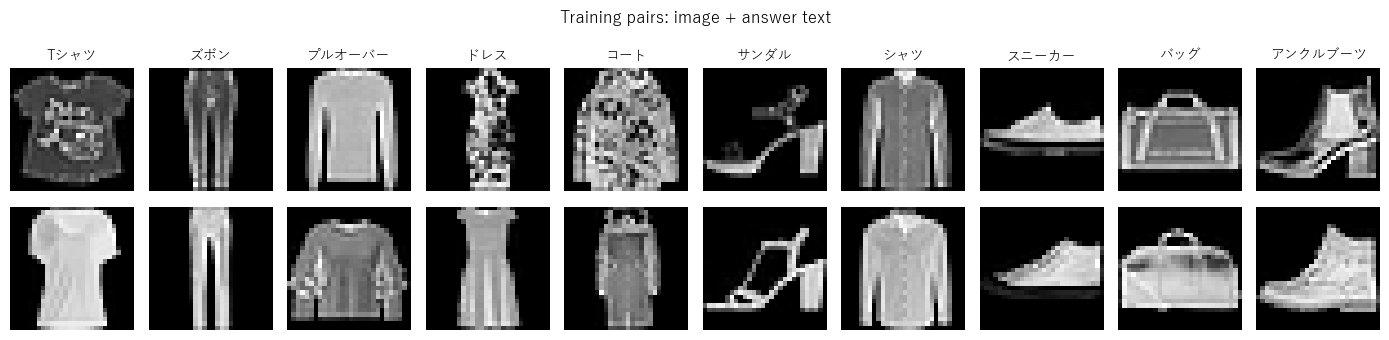

0: T-shirt/top  -> これは？ Tシャツ
1: Trouser      -> これは？ ズボン
2: Pullover     -> これは？ プルオーバー
3: Dress        -> これは？ ドレス
4: Coat         -> これは？ コート
5: Sandal       -> これは？ サンダル
6: Shirt        -> これは？ シャツ
7: Sneaker      -> これは？ スニーカー
8: Bag          -> これは？ バッグ
9: Ankle boot   -> これは？ アンクルブーツ


In [4]:
def split_balanced(labels, train_per_class, val_per_class, seed):
    r = np.random.default_rng(seed)
    train_ids, val_ids = [], []
    for c in range(N_CLASS):
        ids = r.permutation(np.flatnonzero(labels == c))
        assert len(ids) >= train_per_class + val_per_class, f'class {c}: 選択枚数が多すぎます'
        val_ids.extend(ids[:val_per_class])
        train_ids.extend(ids[val_per_class:val_per_class + train_per_class])
    train_ids = r.permutation(np.array(train_ids))
    val_ids = r.permutation(np.array(val_ids))
    assert not np.intersect1d(train_ids, val_ids).size
    return train_ids, val_ids

def normalize(images):
    return images.astype(np.float32) / np.float32(127.5) - np.float32(1.0)

train_ids, val_ids = split_balanced(raw_train_y, TRAIN_PER_CLASS, VAL_PER_CLASS, SEED)
X_train, y_train = normalize(raw_train[train_ids]), raw_train_y[train_ids]
X_val, y_val = normalize(raw_train[val_ids]), raw_train_y[val_ids]
print('train:', len(y_train), 'validation:', len(y_val), 'test (reserved):', len(raw_test_y))
print('train class counts:', np.bincount(y_train, minlength=N_CLASS))

fig, axes = plt.subplots(2, N_CLASS, figsize=(14, 3.6))
for c in range(N_CLASS):
    for row, idx in enumerate(np.flatnonzero(y_train == c)[:2]):
        axes[row, c].imshow(X_train[idx], cmap='gray', vmin=-1, vmax=1)
        axes[row, c].axis('off')
        if row == 0:
            axes[row, c].set_title(class_label(c), fontsize=10)
fig.suptitle('Training pairs: image + answer text')
plt.tight_layout(); plt.show()
for c in range(N_CLASS):
    print(f'{c}: {CLASS_NAMES[c]:12s} -> {PROMPT} {CLASS_NAMES_JA[c]}')

## 3. 文字をトークンにする：TF01と同じ1文字＝1トークン

語彙は、10個の答えと質問文に出てくる文字に、3つの特別なトークンを加えたものです。

| トークン | 役割 |
|---|---|
| `<pad>` | 長さをそろえるための詰め物。損失の計算には使わない |
| `<sep>` | 「ここから答え」の合図。この位置の出力が答えの1文字目になる |
| `<eos>` | 答えの終わり。生成はここで止める |

**入力**は「質問 + `<sep>` + 答え」、**正解（教師）**は「1つ先の文字」です。
質問の部分は予測させないので、正解を `-1`（対象外）にします。**損失は答えの文字と `<eos>` だけで計算します。**

```
入力 :  こ  れ  は  ？  <sep>  ス  ニ  ー  カ  ー   <pad> <pad>
正解 :  -   -   -   -   ス     ニ  ー  カ  ー  <eos>  -     -
```

In [5]:
SPECIALS = ['<pad>', '<sep>', '<eos>']
PAD, SEP, EOS = 0, 1, 2
VOCAB = SPECIALS + sorted(set(''.join(CLASS_NAMES_JA) + PROMPT))
V = len(VOCAB)
TOK2ID = {t: i for i, t in enumerate(VOCAB)}
PROMPT_IDS = [TOK2ID[ch] for ch in PROMPT]
PROMPT_LEN = len(PROMPT_IDS)
SEP_POS = PROMPT_LEN                      # 文字側の列の中での <sep> の位置

def encode(text):
    return [TOK2ID[ch] for ch in text]

def decode(ids):
    return ''.join(VOCAB[i] for i in ids if i >= len(SPECIALS))

def build_text(answer):
    """答えの文字列 → (入力ID列, 正解ID列)。どちらも長さT_LEN。"""
    full = PROMPT_IDS + [SEP] + encode(answer) + [EOS]
    inp = full[:-1]
    tgt = [-1] * PROMPT_LEN + full[PROMPT_LEN + 1:]
    assert len(inp) == len(tgt) <= T_LEN
    pad = T_LEN - len(inp)
    return inp + [PAD] * pad, tgt + [-1] * pad

TEXT_IN = np.array([build_text(name)[0] for name in CLASS_NAMES_JA], dtype=np.int64)   # (10, T_LEN)
TEXT_TGT = np.array([build_text(name)[1] for name in CLASS_NAMES_JA], dtype=np.int64)  # (10, T_LEN)
print(f'vocabulary: {V} tokens')
print(' '.join(f'{i}:{t}' for i, t in enumerate(VOCAB)))
c = 7
print(f'\nexample: {CLASS_NAMES_JA[c]}')
print('input :', ' '.join(f'{VOCAB[i]:>5s}' for i in TEXT_IN[c]))
print('target:', ' '.join(f'{(VOCAB[i] if i >= 0 else "-"):>5s}' for i in TEXT_TGT[c]))
print('answer tokens per class (incl. <eos>):', (TEXT_TGT >= 0).sum(axis=1))

vocabulary: 33 tokens
0:<pad> 1:<sep> 2:<eos> 3:T 4:こ 5:は 6:れ 7:ア 8:オ 9:カ 10:ク 11:グ 12:コ 13:サ 14:シ 15:ス 16:ズ 17:ダ 18:ッ 19:ツ 20:ト 21:ド 22:ニ 23:バ 24:ブ 25:プ 26:ボ 27:ャ 28:ル 29:レ 30:ン 31:ー 32:？

example: スニーカー
input :     こ     れ     は     ？ <sep>     ス     ニ     ー     カ     ー <pad> <pad>
target:     -     -     -     -     ス     ニ     ー     カ     ー <eos>     -     -
answer tokens per class (incl. <eos>): [5 4 7 4 4 5 4 6 4 8]


## 4. 画像をパッチに分け、文字と1本の列にする

パッチ化はTF02と同じです。28×28の画像を `PATCH × PATCH` に区切り、各パッチを1列に並べます（初期設定7×7、16パッチ、各49画素）。
TF03では **CLSトークンを使いません**。答えは文字の位置から取り出すので、画像をまとめる専用のトークンが不要になるためです。

```
位置 :  0 ... 15   16 17 18 19   20     21 ... 27
中身 :  画像パッチ  こ  れ  は  ？   <sep>  答えの文字（最大7文字）
変換 :  Linear     └────── 文字Embedding表 ──────┘
```

画像パッチは `patch @ Wpatch + bpatch`、文字は `Wtok[文字ID]` で、**どちらも同じ64次元のベクトル**になります。
この「同じ次元にそろえて並べる」ことが、画像と文字を1つのTransformerで扱える理由です。

In [6]:
def patchify(images):
    images = np.asarray(images)
    assert images.ndim == 3 and images.shape[1:] == (IMAGE_SIZE, IMAGE_SIZE)
    b = len(images)
    return images.reshape(b, GRID, PATCH, GRID, PATCH).transpose(0, 1, 3, 2, 4).reshape(b, N_PATCH, PATCH_DIM)

train_patches = patchify(X_train)
val_patches = patchify(X_val)
print('images:', X_train.shape, '-> patches:', train_patches.shape)
print('text input for the first 3 training images:')
for i in range(3):
    print('  label', y_train[i], '->', ' '.join(VOCAB[t] for t in TEXT_IN[y_train[i]]))

images: (54000, 28, 28) -> patches: (54000, 16, 49)
text input for the first 3 training images:
  label 3 -> こ れ は ？ <sep> ド レ ス <pad> <pad> <pad> <pad>
  label 8 -> こ れ は ？ <sep> バ ッ グ <pad> <pad> <pad> <pad>
  label 6 -> こ れ は ？ <sep> シ ャ ツ <pad> <pad> <pad> <pad>


## 5. Attentionマスク：誰が誰を見てよいか

TF01は「未来の文字を見せない」因果マスク、TF02はマスクなしでした。TF03は両方を組み合わせます。

- **画像パッチ**：画像パッチ全体を見る。文字は見ない（TF02と同じ双方向）。
- **文字**：画像パッチ全体と、自分より前の文字を見る。後ろの文字は見ない（TF01と同じ因果）。

後ろの文字を見せないので、学習時に答えを全部入力しても「答えを見て答える」ことにはなりません。
また、`<pad>` は必ず列の最後にあるので、前の位置から見えることはなく、専用のマスクは不要です。

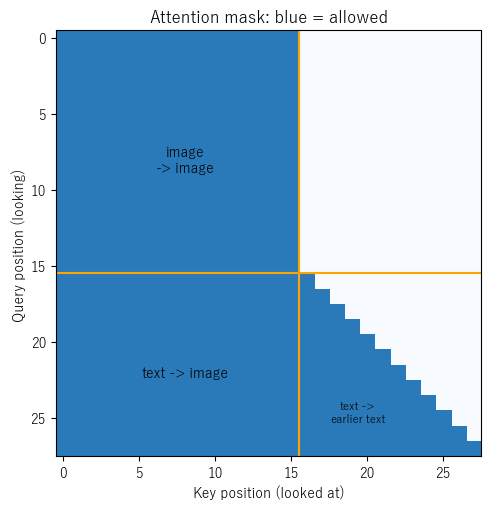

allowed pairs: 526 / 784


In [7]:
def build_mask():
    """True = 見てはいけない。形は (N_SEQ, N_SEQ)、行が見る側、列が見られる側。"""
    blocked = np.zeros((N_SEQ, N_SEQ), dtype=bool)
    blocked[:N_PATCH, N_PATCH:] = True                                        # 画像 → 文字 は見ない
    blocked[N_PATCH:, N_PATCH:] = np.triu(np.ones((T_LEN, T_LEN), dtype=bool), 1)  # 文字 → 後ろの文字 は見ない
    return blocked

MASK = build_mask()
fig, ax = plt.subplots(figsize=(5.2, 5.2))
ax.imshow(~MASK, cmap='Blues', vmin=0, vmax=1.4)
ax.axhline(N_PATCH - .5, color='orange', lw=1.5); ax.axvline(N_PATCH - .5, color='orange', lw=1.5)
ax.set_xlabel('Key position (looked at)'); ax.set_ylabel('Query position (looking)')
ax.set_title('Attention mask: blue = allowed')
ax.text(N_PATCH / 2, N_PATCH / 2, 'image\n-> image', ha='center', va='center', fontsize=10)
ax.text(N_PATCH / 2, N_PATCH + T_LEN / 2, 'text -> image', ha='center', va='center', fontsize=10)
ax.text(N_PATCH + T_LEN * .28, N_PATCH + T_LEN * .72, 'text ->\nearlier text', ha='center', va='center', fontsize=8)
plt.tight_layout(); plt.show()
print('allowed pairs:', int((~MASK).sum()), '/', MASK.size)

## 6. TF01 / TF02の部品を再利用する

`attn_f`、`ffn_f`、`ln_f` はTF01 / TF02と同じ実装です。変更は、Attentionが任意のマスクを受け取るようにした1点だけです。

`SwiGLU(x) = (SiLU(x @ Wg) * (x @ Wu)) @ Wd`

In [8]:
def softmax(x):
    e = np.exp(x - x.max(-1, keepdims=True))
    return e / e.sum(-1, keepdims=True)

def attn_f(x, P, blocked=None):
    """Multi-Head Self-Attention。x: (B, L, D) → (B, L, D)。blocked: (L, L) で True の組は参照しない。"""
    B, L, _ = x.shape
    dt = x.dtype.type
    split = lambda t: t.reshape(B, L, N_HEAD, HD).transpose(0, 2, 1, 3)   # (B, ヘッド, L, HD)
    q = split(x @ P["Wq"])
    k = split(x @ P["Wk"])
    v = split(x @ P["Wv"])
    sc = q @ k.transpose(0, 1, 3, 2) * dt(1 / np.sqrt(HD))                 # (B, ヘッド, L, L)
    if blocked is not None:
        sc = np.where(blocked, dt(-1e9), sc)
    A = softmax(sc)
    o = (A @ v).transpose(0, 2, 1, 3).reshape(B, L, D)                     # ヘッドをつなげる
    return o @ P["Wo"], (x, q, k, v, A, o)

def ffn_f(x, P):
    """SwiGLU 型 MLP。x: (B, L, D) → (B, L, D)"""
    a = x @ P["Wg"]                 # Gate 用
    b = x @ P["Wu"]                 # Up
    sg = 1 / (1 + np.exp(-a))
    s_ = a * sg                     # SiLU(a) = a × sigmoid(a)
    h = s_ * b                      # ゲートを通す（要素ごとの積）
    return h @ P["Wd"], (x, a, b, sg, s_, h)

def ln_f(x, g, b):
    mu = x.mean(-1, keepdims=True)
    var = x.var(-1, keepdims=True)
    inv = 1 / np.sqrt(var + 1e-5)
    xh = (x - mu) * inv
    return xh * g + b, (xh, inv, g)

def make_dropout(shape, rate, rng, dtype):
    if rate == 0 or rng is None:
        return None
    return (rng.random(shape) >= rate).astype(dtype) / dtype(1 - rate)

## 7. 1ブロックのVLMを組み立てる

```
画像パッチ → Linear ─┐
                      ├→ 1本の列にする → 位置Embeddingを足す
文字ID → Embedding表 ─┘
 → LayerNorm → Self-Attention（5章のマスク） → Residual
 → LayerNorm → SwiGLU MLP                     → Residual
 → Final LayerNorm → 文字の位置だけ取り出す → Linear(64→語彙数) → Softmax
```

TF02との違いは、入り口に **文字Embedding表 `Wtok`** が増えたことと、
出口が「CLSから10クラス」ではなく **「文字の各位置から次の文字」** になったことです。
画像エンコーダと言語モデルを別々に用意する実用的なVLMと違い、この教材では1ブロックを画像と文字で共有します。

In [9]:
def init_params(seed=0, dtype=np.float32):
    r = np.random.default_rng(seed)
    n = lambda *shape: r.normal(0, .02, shape)
    p = {
        'Wpatch': r.normal(0, np.sqrt(1 / PATCH_DIM), (PATCH_DIM, D)), 'bpatch': np.zeros(D),
        'Wtok': n(V, D), 'pos': n(1, N_SEQ, D),
        'ln1_g': np.ones(D), 'ln1_b': np.zeros(D),
        'Wq': n(D, D), 'Wk': n(D, D), 'Wv': n(D, D), 'Wo': n(D, D),
        'ln2_g': np.ones(D), 'ln2_b': np.zeros(D),
        'Wg': n(D, D_FF), 'Wu': n(D, D_FF), 'Wd': n(D_FF, D),
        'lnf_g': np.ones(D), 'lnf_b': np.zeros(D),
        'Wout': n(D, V), 'bout': np.zeros(V),
    }
    return {k: v.astype(dtype) for k, v in p.items()}

def forward(P, patches, text_in, targets=None, rng=None, dropout=0.0):
    """パッチ(B,N_PATCH,PATCH_DIM)と文字ID(B,T_LEN) → 文字位置ごとの次の文字。
    targets指定時は損失、未指定時はlogits (B,T_LEN,V) を返す。"""
    B = len(patches)
    dt = P['Wpatch'].dtype.type
    img = patches @ P['Wpatch'] + P['bpatch']            # (B, N_PATCH, D)
    txt = P['Wtok'][text_in]                             # (B, T_LEN, D)
    h0 = np.concatenate([img, txt], axis=1) + P['pos']   # (B, N_SEQ, D)
    masks = tuple(make_dropout(h0.shape, dropout, rng, dt) for _ in range(3))
    m0, m1, m2 = masks
    if m0 is not None:
        h0 = h0 * m0
    n1, c_ln1 = ln_f(h0, P['ln1_g'], P['ln1_b'])
    ao, c_att = attn_f(n1, P, MASK)
    if m1 is not None:
        ao = ao * m1
    h1 = h0 + ao
    n2, c_ln2 = ln_f(h1, P['ln2_g'], P['ln2_b'])
    mo, c_ffn = ffn_f(n2, P)
    if m2 is not None:
        mo = mo * m2
    h2 = h1 + mo
    nf, c_lnf = ln_f(h2, P['lnf_g'], P['lnf_b'])
    text_out = nf[:, N_PATCH:, :]                        # 文字の位置だけ
    logits = text_out @ P['Wout'] + P['bout']            # (B, T_LEN, V)
    cache = dict(patches=patches, text_in=text_in, targets=targets, masks=masks,
                 c_ln1=c_ln1, c_att=c_att, c_ln2=c_ln2, c_ffn=c_ffn,
                 nf=nf, c_lnf=c_lnf, text_out=text_out)
    if targets is None:
        return logits, cache
    valid = targets >= 0                                 # 答えの文字と<eos>だけ
    safe = np.where(valid, targets, 0)
    z = logits - logits.max(axis=-1, keepdims=True)
    log_z = np.log(np.exp(z).sum(axis=-1))
    picked = np.take_along_axis(z, safe[..., None], axis=-1)[..., 0]
    n_valid = int(valid.sum())
    loss = float(((log_z - picked) * valid).sum() / n_valid)
    cache.update(p=softmax(logits), valid=valid, safe=safe, n_valid=n_valid)
    return loss, cache

P = init_params(SEED)
groups = {
    'Patch embedding': ['Wpatch', 'bpatch'],
    'Token embedding': ['Wtok'],
    'Position': ['pos'],
    'Attention Q/K/V/O': ['Wq', 'Wk', 'Wv', 'Wo'],
    'SwiGLU Up/Gate/Down': ['Wu', 'Wg', 'Wd'],
    'LayerNorm x 3': ['ln1_g', 'ln1_b', 'ln2_g', 'ln2_b', 'lnf_g', 'lnf_b'],
    'Output (next token)': ['Wout', 'bout'],
}
for label, names in groups.items():
    print(f'{label:22s}: {sum(P[k].size for k in names):,}')
PARAM_COUNT = sum(w.size for w in P.values())
print(f'TOTAL: {PARAM_COUNT:,} = {PARAM_COUNT / 1000:.3f}K parameters')
yb = y_train[:BATCH]
loss0, demo = forward(P, train_patches[:BATCH], TEXT_IN[yb], TEXT_TGT[yb])
print(f'initial loss={loss0:.3f}, uniform over vocabulary ln({V})={np.log(V):.3f}')
print('sequence:', demo['c_att'][0].shape, '/ attention:', demo['c_att'][4].shape, '/ logits:', demo['p'].shape)
A0 = demo['c_att'][4]
assert np.allclose(A0.sum(axis=-1), 1, atol=1e-5)
assert A0[:, :, MASK].max() < 1e-6, 'マスクした組にAttentionが残っています'

Patch embedding       : 3,200
Token embedding       : 2,112
Position              : 1,792
Attention Q/K/V/O     : 16,384
SwiGLU Up/Gate/Down   : 49,152
LayerNorm x 3         : 384
Output (next token)   : 2,145
TOTAL: 75,169 = 75.169K parameters
initial loss=3.504, uniform over vocabulary ln(33)=3.497
sequence: (32, 28, 64) / attention: (32, 4, 28, 28) / logits: (32, 12, 33)


## 8. 手書きの逆伝播

TF01 / TF02の `ln_b`、`lin_b`、`attn_b`、`ffn_b` をそのまま使います。変更箇所は次の3つです。

- 出口：**答えの文字の位置だけ** に `p - one_hot` の勾配が入る（質問と`<pad>`の位置は0）。
- 文字Embedding：使った文字IDの行に勾配を足し込む（`np.add.at`）。TF01と同じ。
- パッチLinear：画像の位置の勾配から計算する。TF02と同じ。

In [10]:
def ln_b(dy, c):
    xh, inv, g = c
    dg = (dy * xh).sum((0, 1)); db = dy.sum((0, 1)); dxh = dy * g
    dx = inv * (dxh - dxh.mean(-1, keepdims=True) - xh * (dxh * xh).mean(-1, keepdims=True))
    return dx, dg, db

def lin_b(dy, x, W):
    """y = x W の逆伝播。dx と dW を返す"""
    x2 = x.reshape(-1, x.shape[-1]); d2 = dy.reshape(-1, dy.shape[-1])
    return (d2 @ W.T).reshape(x.shape), x2.T @ d2

def attn_b(dout, P, c):
    x, q, k, v, A, o = c
    B, L, _ = x.shape
    dt = x.dtype.type
    g = {}
    do, g["Wo"] = lin_b(dout, o, P["Wo"])
    do = do.reshape(B, L, N_HEAD, HD).transpose(0, 2, 1, 3)
    dA = do @ v.transpose(0, 1, 3, 2)
    dv = A.transpose(0, 1, 3, 2) @ do
    dsc = A * (dA - (dA * A).sum(-1, keepdims=True)) * dt(1 / np.sqrt(HD))   # softmax の逆伝播
    dq = dsc @ k
    dk = dsc.transpose(0, 1, 3, 2) @ q
    merge = lambda t: t.transpose(0, 2, 1, 3).reshape(B, L, D)
    dxq, g["Wq"] = lin_b(merge(dq), x, P["Wq"])
    dxk, g["Wk"] = lin_b(merge(dk), x, P["Wk"])
    dxv, g["Wv"] = lin_b(merge(dv), x, P["Wv"])
    return dxq + dxk + dxv, g

def ffn_b(dout, P, c):
    x, a, b, sg, s_, h = c
    g = {}
    dh, g["Wd"] = lin_b(dout, h, P["Wd"])
    ds, db = dh * b, dh * s_
    da = ds * (sg * (1 + a * (1 - sg)))                                       # SiLU の微分
    dxa, g["Wg"] = lin_b(da, x, P["Wg"])
    dxb, g["Wu"] = lin_b(db, x, P["Wu"])
    return dxa + dxb, g

def backward(P, cache):
    m0, m1, m2 = cache['masks']
    G = {}
    dl = cache['p'].copy()                                   # (B, T_LEN, V)
    np.put_along_axis(dl, cache['safe'][..., None],
                      np.take_along_axis(dl, cache['safe'][..., None], axis=-1) - 1, axis=-1)
    dl *= (cache['valid'][..., None] / cache['n_valid']).astype(dl.dtype)   # 答えの位置だけ残す
    dtext, G['Wout'] = lin_b(dl, cache['text_out'], P['Wout'])
    G['bout'] = dl.sum(axis=(0, 1))
    dnf = np.zeros_like(cache['nf'])
    dnf[:, N_PATCH:, :] = dtext
    dh2, G['lnf_g'], G['lnf_b'] = ln_b(dnf, cache['c_lnf'])

    dmo = dh2 * m2 if m2 is not None else dh2
    dn2, gf = ffn_b(dmo, P, cache['c_ffn']); G.update(gf)
    dh1_ln, G['ln2_g'], G['ln2_b'] = ln_b(dn2, cache['c_ln2'])
    dh1 = dh2 + dh1_ln
    dao = dh1 * m1 if m1 is not None else dh1
    dn1, ga = attn_b(dao, P, cache['c_att']); G.update(ga)
    dh0_ln, G['ln1_g'], G['ln1_b'] = ln_b(dn1, cache['c_ln1'])
    dh0 = dh1 + dh0_ln
    if m0 is not None:
        dh0 = dh0 * m0
    G['pos'] = dh0.sum(axis=0, keepdims=True)
    G['Wtok'] = np.zeros_like(P['Wtok'])
    np.add.at(G['Wtok'], cache['text_in'], dh0[:, N_PATCH:, :])            # 文字Embedding表
    dimg = dh0[:, :N_PATCH, :]
    _, G['Wpatch'] = lin_b(dimg, cache['patches'], P['Wpatch'])            # パッチLinear
    G['bpatch'] = dimg.sum(axis=(0, 1))
    assert set(G) == set(P)
    return G

## 9. 勾配チェック：数値微分と一致するか

float64・ドロップアウトなしで、各パラメータ配列の2要素を中心差分と比較します。
文字Embedding表は、この入力で実際に使われた文字の行から選びます。
一致しない場合はassertで停止し、誤った逆伝播のまま学習を続けません。

In [11]:
Pc = init_params(seed=1, dtype=np.float64)
xc = train_patches[:3].astype(np.float64)
tin, ttg = TEXT_IN[y_train[:3]], TEXT_TGT[y_train[:3]]
_, cc = forward(Pc, xc, tin, ttg)
Gc = backward(Pc, cc)
rcheck = np.random.default_rng(5)
worst_rel, worst_abs, checked = 0.0, 0.0, 0
for name in Pc:
    for _ in range(2):
        idx = tuple(int(rcheck.integers(s)) for s in Pc[name].shape)
        if name == 'Wtok':
            idx = (int(rcheck.choice(tin[:, :SEP_POS + 2].ravel())), idx[1])
        old = Pc[name][idx]
        eps = 1e-5
        Pc[name][idx] = old + eps; lp, _ = forward(Pc, xc, tin, ttg)
        Pc[name][idx] = old - eps; lm, _ = forward(Pc, xc, tin, ttg)
        Pc[name][idx] = old
        numeric, analytic = (lp - lm) / (2 * eps), float(Gc[name][idx])
        absolute = abs(numeric - analytic)
        relative = absolute / max(1e-6, abs(numeric) + abs(analytic))
        worst_abs, worst_rel = max(worst_abs, absolute), max(worst_rel, relative)
        checked += 1
        assert np.isclose(numeric, analytic, rtol=2e-3, atol=2e-7), (name, idx, numeric, analytic)
print(f'Gradient check PASS: {checked} values, max abs={worst_abs:.2e}, max rel={worst_rel:.2e}')

Gradient check PASS: 38 values, max abs=4.71e-11, max rel=2.00e-07


## 10. 生成する：1文字ずつ答えを作る

推論では答えを入力しません。「画像 + これは？ + `<sep>`」だけを入れ、`<sep>` の位置の出力から1文字目を選びます。
選んだ文字を列の後ろに足してもう一度計算し、次の文字を選びます。`<eos>` が出たら終了です（TF01の和歌生成と同じ自己回帰）。
ここでは毎回、確率が最大の文字を選びます（greedy）。同じ画像には常に同じ答えを返します。

評価は2通りです。
- **検証損失**：正解の文字を入力した状態で、次の文字をどれだけ当てられるか（学習時と同じ計算）。
- **完全一致の正解率**：実際に生成した文字列が、正解の文字列と1文字も違わず一致した割合。

学習前のモデルの答えも記録し、学習後と比べます。

In [12]:
def generate(P, patches, batch_size=None):
    """画像パッチ → 生成した文字列のリスト（greedy）。"""
    batch_size = EVAL_BATCH if batch_size is None else min(batch_size, SAFE_BATCH)
    results = []
    for start in range(0, len(patches), batch_size):
        pt = patches[start:start + batch_size]
        B = len(pt)
        text = np.full((B, T_LEN), PAD, dtype=np.int64)
        text[:, :PROMPT_LEN] = PROMPT_IDS
        text[:, SEP_POS] = SEP
        done = np.zeros(B, dtype=bool)
        out = [[] for _ in range(B)]
        for s in range(MAX_ANS + 1):
            pos = SEP_POS + s
            logits, _ = forward(P, pt, text)
            nxt = logits[:, pos, :].argmax(axis=-1)
            for b in np.flatnonzero(~done):
                if nxt[b] < len(SPECIALS):      # <eos>など → 終了
                    done[b] = True
                else:
                    out[b].append(int(nxt[b]))
            if done.all() or pos + 1 >= T_LEN:
                break
            text[:, pos + 1] = nxt
        results.extend(decode(ids) for ids in out)
    return results

def exact_match(strings, labels):
    return float(np.mean([s == CLASS_NAMES_JA[c] for s, c in zip(strings, labels)]))

def teacher_forced_loss(P, patches, labels):
    total, count = 0.0, 0
    for start in range(0, len(patches), EVAL_BATCH):
        lab = labels[start:start + EVAL_BATCH]
        loss, cache = forward(P, patches[start:start + EVAL_BATCH], TEXT_IN[lab], TEXT_TGT[lab])
        total += loss * cache['n_valid']; count += cache['n_valid']
    return total / count

# 学習中に生成で測る検証画像（クラスごとに同数、固定）
val_gen_idx = np.concatenate([np.flatnonzero(y_val == c)[:VAL_GEN_PER_CLASS] for c in range(N_CLASS)])
example_ids = np.array([np.flatnonzero(y_val == c)[0] for c in range(N_CLASS)])

P_initial = init_params(SEED)
before_loss = teacher_forced_loss(P_initial, val_patches, y_val)
before_gen = generate(P_initial, val_patches[val_gen_idx])
before_acc = exact_match(before_gen, y_val[val_gen_idx])
before_examples = generate(P_initial, val_patches[example_ids])
print(f'Before training: validation loss={before_loss:.4f}, exact match={before_acc:.2%} ({len(val_gen_idx)} images)')
for c, s in zip(range(N_CLASS), before_examples):
    print(f'  correct: {CLASS_NAMES_JA[c]:8s} generated: {s!r}')

Before training: validation loss=3.5119, exact match=0.00% (1000 images)
  correct: Tシャツ     generated: 'ブ'
  correct: ズボン      generated: 'ブ'
  correct: プルオーバー   generated: 'ブオググググググ'
  correct: ドレス      generated: 'ブオググググググ'
  correct: コート      generated: 'ブオググググググ'
  correct: サンダル     generated: 'ブオググググググ'
  correct: シャツ      generated: 'ブ'
  correct: スニーカー    generated: 'ブオググググググ'
  correct: バッグ      generated: 'ブ'
  correct: アンクルブーツ  generated: 'ブ'


## 11. AdamWで学習する

各エポックの先頭で学習画像をシャッフルし、`BATCH` 枚ずつ重複なしで取り出します。
画像ごとに、正解クラスの「入力ID列」と「正解ID列」を表から引くだけなので、文の側の前処理はほとんどありません。
各エポック末に検証損失と、検証画像（各クラス100枚）での完全一致の正解率を測り、**検証損失が最小のモデル**を選びます。

順伝播 → 損失 → 逆伝播 → 勾配クリッピング → AdamWの順で更新します。
重み減衰の対象はLinearの重みだけです（Embedding表・位置・LayerNorm・バイアスは対象外）。
学習の関数は、最後の「学習件数を変えて試す」でも使います。

In [13]:
DECAY_KEYS = {'Wpatch', 'Wq', 'Wk', 'Wv', 'Wo', 'Wg', 'Wu', 'Wd', 'Wout'}

def train_model(patches, labels, epochs, max_seconds=None, seed=SEED, verbose=True):
    P = init_params(seed)
    m = {k: np.zeros_like(w) for k, w in P.items()}
    v2 = {k: np.zeros_like(w) for k, w in P.items()}
    rng = np.random.default_rng(seed)
    steps_per_epoch = (len(labels) + BATCH - 1) // BATCH
    steps = epochs * steps_per_epoch
    hist = {'step': [0], 'train_loss': [None], 'val_loss': [before_loss],
            'val_exact_match': [before_acc], 'seconds': [0.0]}
    best_loss, best_step = float('inf'), 0
    best_P = {k: w.copy() for k, w in P.items()}
    run_loss, samples_seen, stop_reason = [], 0, 'EPOCHS'
    t0 = time.perf_counter()
    for step in range(1, steps + 1):
        lr = LR * min(1.0, step / 50) * (0.1 + 0.9 * 0.5 * (1 + np.cos(np.pi * step / steps)))
        batch_index = (step - 1) % steps_per_epoch
        if batch_index == 0:
            epoch_order = rng.permutation(len(labels))
        indices = epoch_order[batch_index * BATCH:(batch_index + 1) * BATCH]
        samples_seen += len(indices)
        lab = labels[indices]
        loss, cache = forward(P, patches[indices], TEXT_IN[lab], TEXT_TGT[lab], rng=rng, dropout=DROPOUT)
        G = backward(P, cache)
        assert np.isfinite(loss) and all(np.isfinite(g).all() for g in G.values()), '損失または勾配が非有限です'
        run_loss.append(loss)
        grad_norm = float(np.sqrt(sum(np.sum(g.astype(np.float64)**2) for g in G.values())))
        scale = min(1.0, 1.0 / (grad_norm + 1e-6))
        for k in P:
            g = G[k] * scale
            m[k] = .9 * m[k] + .1 * g
            v2[k] = .999 * v2[k] + .001 * g * g
            mh = m[k] / (1 - .9**step)
            vh = v2[k] / (1 - .999**step)
            if k in DECAY_KEYS:
                P[k] -= lr * WEIGHT_DECAY * P[k]
            P[k] -= lr * mh / (np.sqrt(vh) + 1e-8)
        elapsed = time.perf_counter() - t0
        time_up = max_seconds is not None and elapsed >= max_seconds
        if step % steps_per_epoch == 0 or step == steps or time_up:
            vl = teacher_forced_loss(P, val_patches, y_val)
            va = exact_match(generate(P, val_patches[val_gen_idx]), y_val[val_gen_idx])
            elapsed = time.perf_counter() - t0
            hist['step'].append(step); hist['train_loss'].append(float(np.mean(run_loss)))
            hist['val_loss'].append(vl); hist['val_exact_match'].append(va); hist['seconds'].append(elapsed)
            if vl < best_loss:
                best_loss, best_step = vl, step
                best_P = {k: w.copy() for k, w in P.items()}
            if verbose:
                print(f'step {step:5d}/{steps}  train loss={np.mean(run_loss):.3f}  '
                      f'val loss={vl:.3f}  val exact match={va:.1%}  {elapsed:.1f}s', flush=True)
            run_loss = []
        if time_up:
            stop_reason = 'MAX_TRAIN_SECONDS'
            break
    return dict(P=best_P, P_last=P, hist=hist, best_step=best_step, steps=steps, completed_steps=step,
                steps_per_epoch=steps_per_epoch, samples_seen=samples_seen,
                seconds=time.perf_counter() - t0, stop_reason=stop_reason)

run = train_model(train_patches, y_train, EPOCHS, MAX_TRAIN_SECONDS)
P, P_last, hist = run['P'], run['P_last'], run['hist']
TRAIN_SECONDS = run['seconds']
after_loss = teacher_forced_loss(P, val_patches, y_val)
val_gen_all = generate(P, val_patches)
after_acc = exact_match(val_gen_all, y_val)
print(f"Finished: {run['completed_steps']} steps, {TRAIN_SECONDS:.1f}s, reason={run['stop_reason']}")
print(f"Samples seen: {run['samples_seen']:,} ({run['samples_seen'] / len(y_train):.2f} epochs)")
print(f"Selected by validation loss: step={run['best_step']}, val loss {before_loss:.3f} -> {after_loss:.3f}")
print(f'Validation exact match (all {len(y_val)} images): {after_acc:.2%}')

step  1688/13504  train loss=0.209  val loss=0.112  val exact match=80.8%  23.5s
step  3376/13504  train loss=0.102  val loss=0.103  val exact match=81.9%  45.2s
step  5064/13504  train loss=0.091  val loss=0.094  val exact match=83.4%  66.5s
step  6752/13504  train loss=0.085  val loss=0.090  val exact match=83.2%  88.3s
step  8440/13504  train loss=0.079  val loss=0.081  val exact match=85.4%  110.2s
step 10128/13504  train loss=0.073  val loss=0.079  val exact match=85.0%  131.1s
step 11816/13504  train loss=0.068  val loss=0.076  val exact match=85.6%  152.9s
step 13504/13504  train loss=0.066  val loss=0.073  val exact match=85.9%  174.5s
Finished: 13504 steps, 174.5s, reason=EPOCHS
Samples seen: 432,000 (8.00 epochs)
Selected by validation loss: step=13504, val loss 3.512 -> 0.073
Validation exact match (all 6000 images): 86.33%


step  5064/13504  train loss=0.091  val loss=0.094  val exact match=83.4%  64.2s


step  6752/13504  train loss=0.085  val loss=0.090  val exact match=83.2%  84.8s


step  8440/13504  train loss=0.079  val loss=0.081  val exact match=85.4%  105.7s


step 10128/13504  train loss=0.073  val loss=0.079  val exact match=85.0%  126.2s


step 11816/13504  train loss=0.068  val loss=0.076  val exact match=85.6%  146.7s


step 13504/13504  train loss=0.066  val loss=0.073  val exact match=85.9%  167.3s


Finished: 13504 steps, 167.3s, reason=EPOCHS
Samples seen: 432,000 (8.00 epochs)
Selected by validation loss: step=13504, val loss 3.512 -> 0.073
Validation exact match (all 6000 images): 86.33%


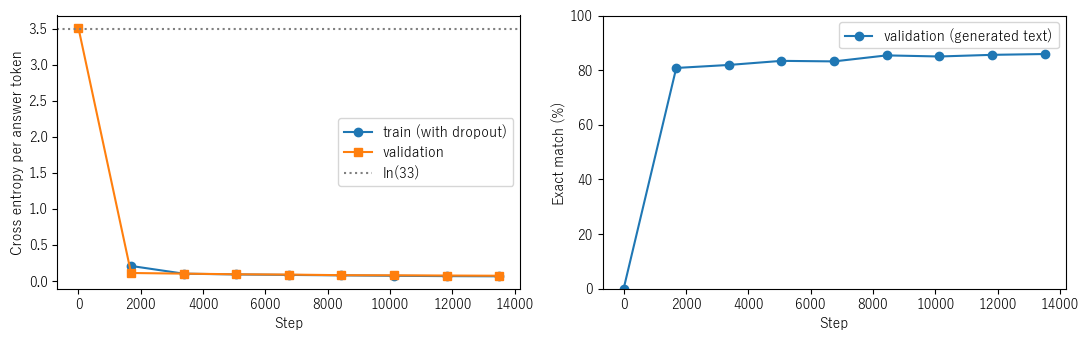

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(hist['step'][1:], hist['train_loss'][1:], 'o-', label='train (with dropout)')
axes[0].plot(hist['step'], hist['val_loss'], 's-', label='validation')
axes[0].axhline(np.log(V), color='gray', ls=':', label=f'ln({V})')
axes[0].set_xlabel('Step'); axes[0].set_ylabel('Cross entropy per answer token'); axes[0].legend()
axes[1].plot(hist['step'], np.array(hist['val_exact_match']) * 100, 'o-', label='validation (generated text)')
axes[1].set_xlabel('Step'); axes[1].set_ylabel('Exact match (%)'); axes[1].set_ylim(0, 100)
axes[1].legend()
plt.tight_layout(); plt.show()

## 12. 同じ画像で学習前後の答えを比べる

クラスごとに検証画像を1枚ずつ選び、**同じ画像に対する生成結果を学習前・学習後で並べます**。
Tは正解、Pは生成した文字列です。緑は完全一致、赤は不一致です。
学習前は、同じ文字の繰り返しや意味のない並びになります。

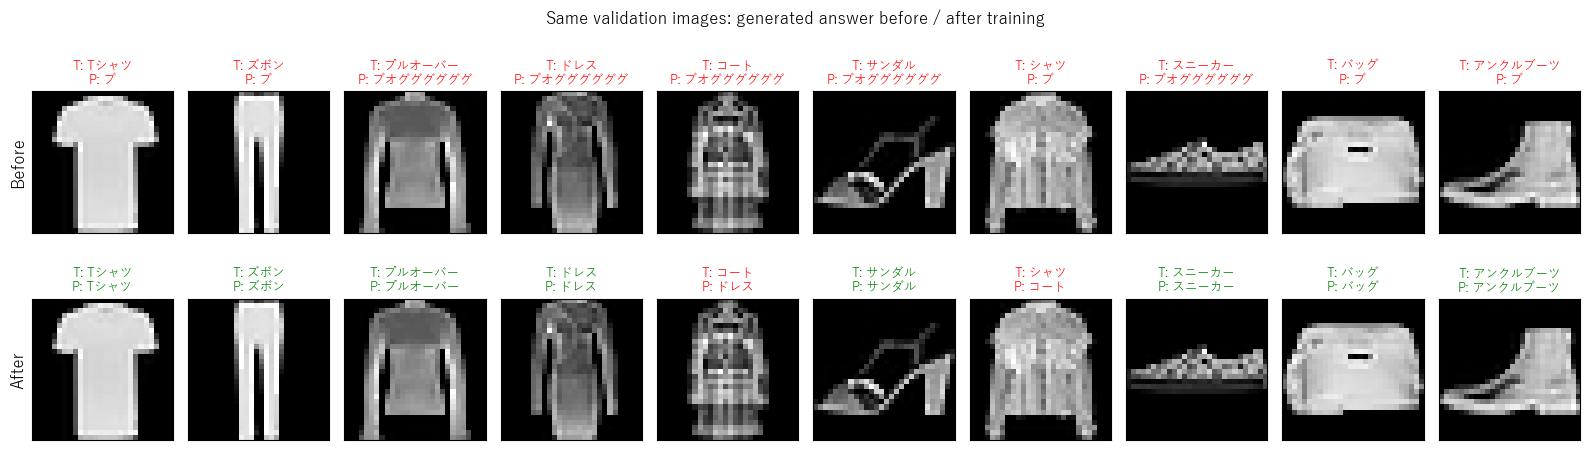

correct: Tシャツ     before: 'ブ'          after: 'Tシャツ'
correct: ズボン      before: 'ブ'          after: 'ズボン'
correct: プルオーバー   before: 'ブオググググググ'   after: 'プルオーバー'
correct: ドレス      before: 'ブオググググググ'   after: 'ドレス'
correct: コート      before: 'ブオググググググ'   after: 'ドレス'
correct: サンダル     before: 'ブオググググググ'   after: 'サンダル'
correct: シャツ      before: 'ブ'          after: 'コート'
correct: スニーカー    before: 'ブオググググググ'   after: 'スニーカー'
correct: バッグ      before: 'ブ'          after: 'バッグ'
correct: アンクルブーツ  before: 'ブ'          after: 'アンクルブーツ'


In [15]:
after_examples = generate(P, val_patches[example_ids])
fig, axes = plt.subplots(2, N_CLASS, figsize=(16, 5))
for row, (title, texts) in enumerate([('Before', before_examples), ('After', after_examples)]):
    for col, idx in enumerate(example_ids):
        ax = axes[row, col]
        true = int(y_val[idx]); ok = texts[col] == CLASS_NAMES_JA[true]
        ax.imshow(X_val[idx], cmap='gray', vmin=-1, vmax=1)
        ax.set_title(f'T: {class_label(true)}\nP: {show_text(texts[col])}', fontsize=9, color='green' if ok else 'red')
        ax.set_xticks([]); ax.set_yticks([])
        if col == 0:
            ax.set_ylabel(title, fontsize=12)
fig.suptitle('Same validation images: generated answer before / after training')
plt.tight_layout(); plt.show()
for c in range(N_CLASS):
    print(f'correct: {CLASS_NAMES_JA[c]:8s} before: {before_examples[c]!r:12s} after: {after_examples[c]!r}')

## 13. 公式テスト10,000枚で最終評価する

ここで初めて公式テストを使います。10,000枚それぞれについて答えを生成し、正解の文字列と比べます。

分類モデル（TF02）は必ず10クラスのどれかを返しますが、**生成モデルは10語以外の文字列も出力できます**
（例：2つの語が混ざった文字列）。そこで混同行列に「その他」の列を加え、10語以外の出力の数も数えます。
混同行列は **行＝正解、列＝生成した文字列** です。

Official test exact match: 86.38% (8638/10000), generation 15.4s
Outputs that are not one of the 10 answers: 0
answer      precision     recall         F1
Tシャツ         0.831      0.794      0.812
ズボン          0.987      0.968      0.977
プルオーバー      0.802      0.739      0.769
ドレス          0.832      0.908      0.868
コート          0.756      0.817      0.785
サンダル        0.945      0.934      0.940
シャツ          0.669      0.641      0.655
スニーカー      0.927      0.921      0.924
バッグ          0.961      0.959      0.960
アンクルブーツ      0.926      0.957      0.941
macro           0.864      0.864      0.863


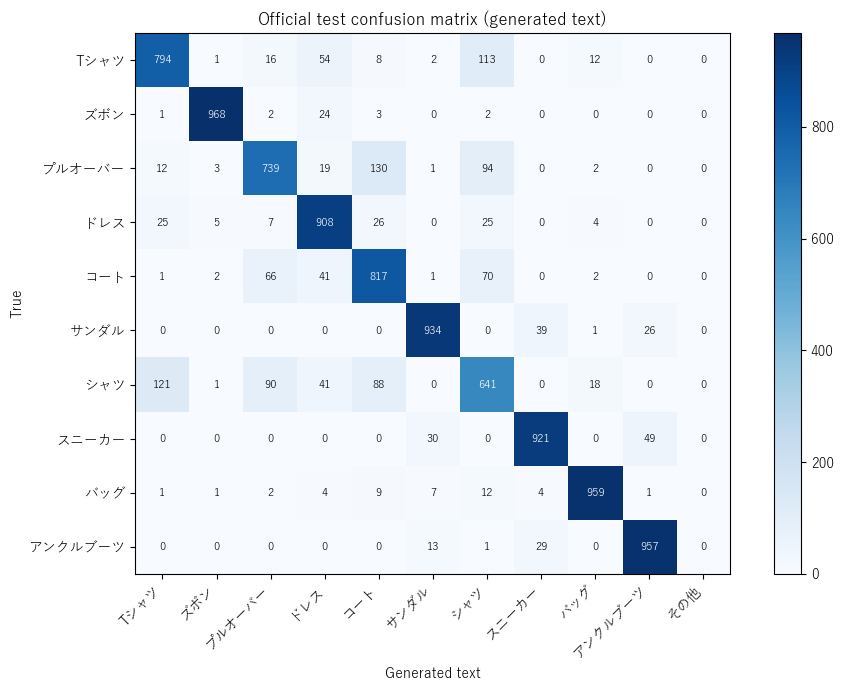

In [16]:
test_patches = patchify(normalize(raw_test))
t_gen0 = time.perf_counter()
test_gen = generate(P, test_patches)
GEN_SECONDS = time.perf_counter() - t_gen0
NAME2ID = {name: i for i, name in enumerate(CLASS_NAMES_JA)}
test_pred = np.array([NAME2ID.get(s, N_CLASS) for s in test_gen])     # 10 = 10語以外
confusion = np.zeros((N_CLASS, N_CLASS + 1), dtype=np.int64)
np.add.at(confusion, (raw_test_y, test_pred), 1)
assert confusion.sum() == 10000
correct = int(np.trace(confusion[:, :N_CLASS]))
TEST_EXACT_MATCH = correct / 10000
INVALID_OUTPUTS = int(confusion[:, N_CLASS].sum())
tp = np.diag(confusion[:, :N_CLASS]).astype(np.float64)
precision = tp / np.maximum(confusion[:, :N_CLASS].sum(axis=0), 1)
recall = tp / np.maximum(confusion.sum(axis=1), 1)
f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
print(f'Official test exact match: {TEST_EXACT_MATCH:.2%} ({correct}/10000), generation {GEN_SECONDS:.1f}s')
print(f'Outputs that are not one of the 10 answers: {INVALID_OUTPUTS}')
if INVALID_OUTPUTS:
    others, counts = np.unique([s for s in test_gen if s not in NAME2ID], return_counts=True)
    for s, n in sorted(zip(others, counts), key=lambda t: -t[1])[:10]:
        print(f'   {s!r}: {n}')
print(f'{"answer":10s} {"precision":>10s} {"recall":>10s} {"F1":>10s}')
for i in range(N_CLASS):
    pad = ' ' * max(0, 10 - 2 * len(CLASS_NAMES_JA[i]) + CLASS_NAMES_JA[i].count('T'))
    print(f'{CLASS_NAMES_JA[i]}{pad} {precision[i]:10.3f} {recall[i]:10.3f} {f1[i]:10.3f}')
print(f'{"macro":10s} {precision.mean():10.3f} {recall.mean():10.3f} {f1.mean():10.3f}')

fig, ax = plt.subplots(figsize=(10, 7))
im = ax.imshow(confusion, cmap='Blues')
for i in range(N_CLASS):
    for j in range(N_CLASS + 1):
        ax.text(j, i, str(confusion[i, j]), ha='center', va='center', fontsize=8,
                color='white' if confusion[i, j] > confusion.max() / 2 else 'black')
ax.set_xticks(range(N_CLASS + 1))
ax.set_xticklabels([class_label(c) for c in range(N_CLASS)] + ['その他' if JA_FONT else 'other'], rotation=45, ha='right')
ax.set_yticks(range(N_CLASS)); ax.set_yticklabels([class_label(c) for c in range(N_CLASS)])
ax.set_xlabel('Generated text'); ax.set_ylabel('True'); ax.set_title('Official test confusion matrix (generated text)')
fig.colorbar(im, ax=ax); plt.tight_layout(); plt.show()

### 間違えた画像を見る

Tシャツ・シャツ・プルオーバー・コートは、小さい白黒画像では似て見えます。
間違いの中心がTF02と同じ組み合わせであれば、**誤りの原因は文字の生成ではなく画像の見分け**にあると分かります。

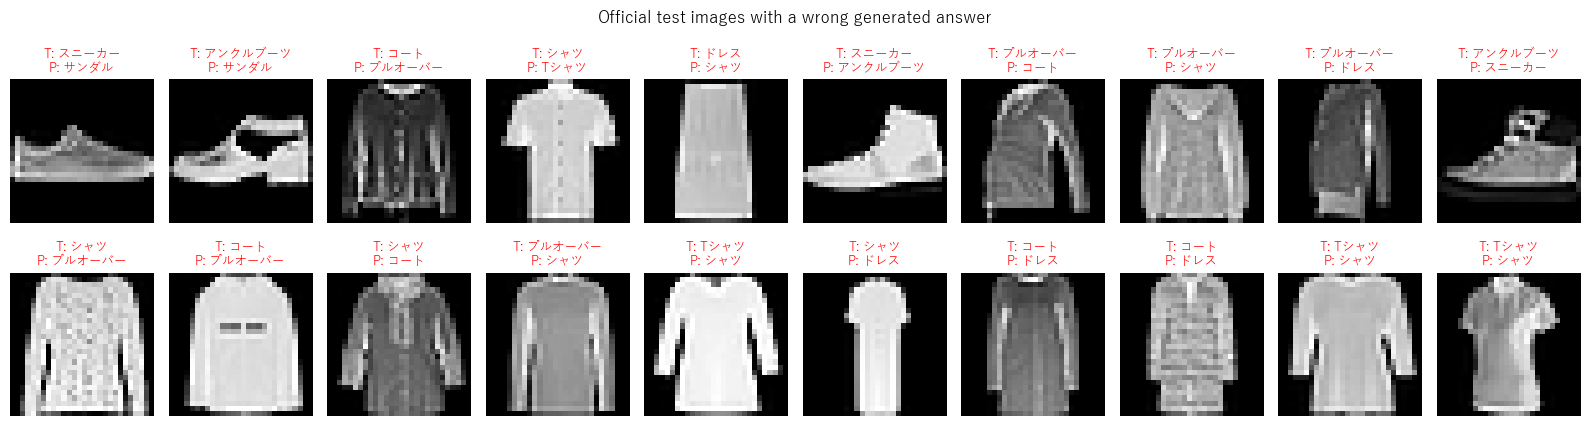

In [17]:
wrong_ids = np.flatnonzero(test_pred != raw_test_y)[:20]
if len(wrong_ids):
    fig, axes = plt.subplots(2, 10, figsize=(16, 4.6))
    for ax, idx in zip(axes.flat, wrong_ids):
        ax.imshow(raw_test[idx], cmap='gray', vmin=0, vmax=255)
        ax.set_title(f'T: {class_label(int(raw_test_y[idx]))}\nP: {show_text(test_gen[idx])}', fontsize=9, color='red')
    for ax in axes.flat:
        ax.axis('off')
    fig.suptitle('Official test images with a wrong generated answer')
    plt.tight_layout(); plt.show()
else:
    print('この実行ではテスト画像の誤りがありませんでした。')

## 14. 1文字ずつの生成を追う

1枚の画像について、各ステップで確率の高い文字の上位3つを表示します。
10個の答えは1文字目がほぼ異なるので（「シャツ」と「サンダル」「スニーカー」は2文字目で分かれます）、
**最初の1〜2文字でどの語になるかが決まり**、その後の文字はほぼ100%の確率で続きます。
つまり、画像を見分ける仕事は最初の文字を選ぶ時点でほぼ終わっています。

`TRACE_INDEX` を変えると、別のテスト画像で試せます。

test image 0: correct = アンクルブーツ, generated = 'アンクルブーツ'
step | 1st choice      | 2nd choice      | 3rd choice
   1 | ア       99.5%   | ス        0.4%   | サ        0.1%  
   2 | ン      100.0%   | ル        0.0%   | オ        0.0%  
   3 | ク      100.0%   | ニ        0.0%   | ー        0.0%  
   4 | ル      100.0%   | <eos>    0.0%   | ブ        0.0%  
   5 | ブ      100.0%   | オ        0.0%   | コ        0.0%  
   6 | ー      100.0%   | バ        0.0%   | ン        0.0%  
   7 | ツ      100.0%   | ン        0.0%   | ー        0.0%  
   8 | <eos>  100.0%   | ア        0.0%   | ズ        0.0%  


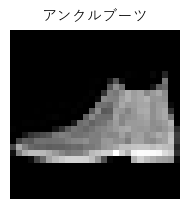

In [18]:
TRACE_INDEX = 0   # 公式テスト画像の番号（0〜9999）
assert 0 <= TRACE_INDEX < len(raw_test_y)

def trace_generation(P, patch):
    text = np.full((1, T_LEN), PAD, dtype=np.int64)
    text[0, :PROMPT_LEN] = PROMPT_IDS
    text[0, SEP_POS] = SEP
    rows = []
    for s in range(MAX_ANS + 1):
        pos = SEP_POS + s
        logits, _ = forward(P, patch, text)
        probs = softmax(logits[0, pos])
        top = np.argsort(-probs)[:3]
        rows.append([(VOCAB[i], float(probs[i])) for i in top])
        if top[0] < len(SPECIALS) or pos + 1 >= T_LEN:
            break
        text[0, pos + 1] = top[0]
    return rows

rows = trace_generation(P, test_patches[TRACE_INDEX:TRACE_INDEX + 1])
print(f'test image {TRACE_INDEX}: correct = {CLASS_NAMES_JA[raw_test_y[TRACE_INDEX]]}, generated = {test_gen[TRACE_INDEX]!r}')
print('step | 1st choice      | 2nd choice      | 3rd choice')
for s, row in enumerate(rows, 1):
    print(f'{s:4d} | ' + ' | '.join(f'{tok:<6s}{p:7.1%}  ' for tok, p in row))
plt.figure(figsize=(2.2, 2.2))
plt.imshow(raw_test[TRACE_INDEX], cmap='gray', vmin=0, vmax=255); plt.axis('off')
plt.title(show_text(test_gen[TRACE_INDEX]), fontsize=11); plt.show()

## 15. Attentionを見る：答えの1文字目を決める位置が、どのパッチを参照したか

`<sep>` の位置（＝答えの1文字目を出力する位置）から各画像パッチへのAttentionを、`GRID × GRID` に並べます。
TF02ではCLSが画像を見ていましたが、TF03では **文字の位置が直接、画像を見ています**。
画像パッチへの重みの合計が1に満たない分は、質問文「これは？」と `<sep>` 自身に向いています。

Attentionは内部の情報の混ぜ方です。**明るい場所がそのまま「判断理由」になるとは限りません。**

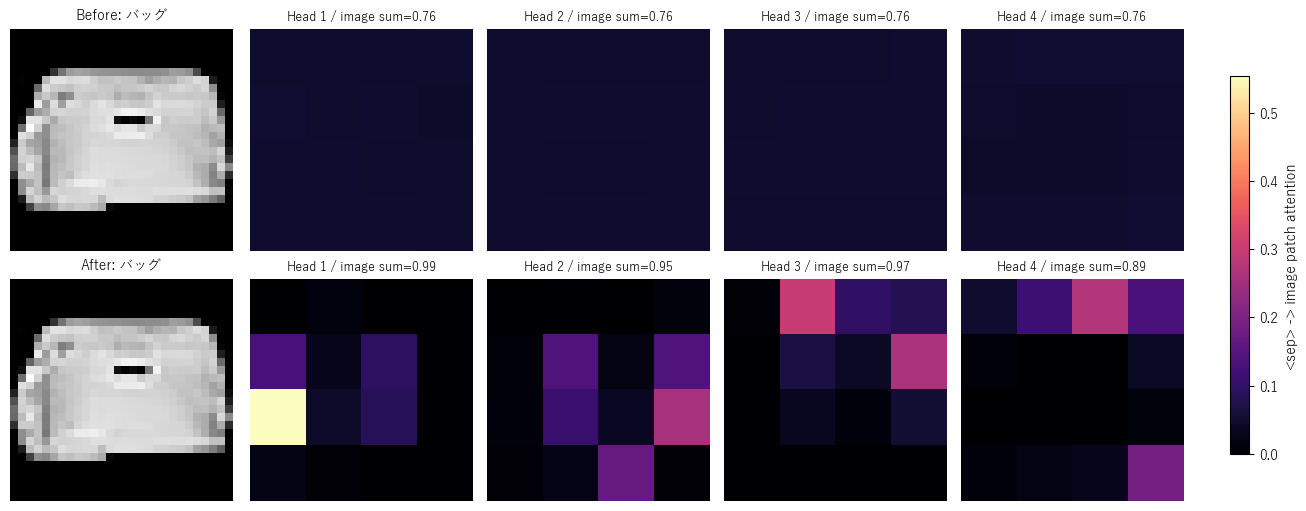

In [19]:
ATTENTION_SAMPLE = int(example_ids[8])  # 検証データのバッグ。別の画像番号に変更できます。
prompt_only = np.full((1, T_LEN), PAD, dtype=np.int64)
prompt_only[0, :PROMPT_LEN] = PROMPT_IDS
prompt_only[0, SEP_POS] = SEP
q_pos = N_PATCH + SEP_POS
_, cache_before = forward(P_initial, val_patches[ATTENTION_SAMPLE:ATTENTION_SAMPLE + 1], prompt_only)
_, cache_after = forward(P, val_patches[ATTENTION_SAMPLE:ATTENTION_SAMPLE + 1], prompt_only)
maps_before = cache_before['c_att'][4][0, :, q_pos, :N_PATCH].reshape(N_HEAD, GRID, GRID)
maps_after = cache_after['c_att'][4][0, :, q_pos, :N_PATCH].reshape(N_HEAD, GRID, GRID)
vmax = max(float(maps_before.max()), float(maps_after.max()), 1e-6)
fig, axes = plt.subplots(2, N_HEAD + 1, figsize=(13, 5), constrained_layout=True)
for row, (label, maps) in enumerate([('Before', maps_before), ('After', maps_after)]):
    axes[row, 0].imshow(X_val[ATTENTION_SAMPLE], cmap='gray', vmin=-1, vmax=1)
    axes[row, 0].set_title(f'{label}: {class_label(int(y_val[ATTENTION_SAMPLE]))}', fontsize=10)
    axes[row, 0].axis('off')
    for h in range(N_HEAD):
        im = axes[row, h + 1].imshow(maps[h], cmap='magma', vmin=0, vmax=vmax)
        axes[row, h + 1].set_title(f'Head {h + 1} / image sum={maps[h].sum():.2f}', fontsize=9)
        axes[row, h + 1].axis('off')
fig.colorbar(im, ax=axes[:, 1:].ravel().tolist(), label='<sep> -> image patch attention', shrink=.8)
plt.show()

## 16. 学習結果を保存する

`tf03_results/patch_7/` など、パッチサイズ別のフォルダにモデルと実測メトリクスを保存します。
`tf03_vlm_model.npz` は検証損失最小のモデル、`tf03_vlm_model_last.npz` は最終更新時点のモデルです。

In [20]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
config = dict(D=D, N_HEAD=N_HEAD, HD=HD, D_FF=D_FF, PATCH=PATCH, IMAGE_SIZE=IMAGE_SIZE, GRID=GRID,
              N_PATCH=N_PATCH, PATCH_DIM=PATCH_DIM, T_LEN=T_LEN, N_SEQ=N_SEQ, vocab=VOCAB, prompt=PROMPT,
              answers=CLASS_NAMES_JA, class_names=CLASS_NAMES,
              TRAIN_PER_CLASS=TRAIN_PER_CLASS, VAL_PER_CLASS=VAL_PER_CLASS, EPOCHS=EPOCHS, BATCH=BATCH,
              MAX_TRAIN_SECONDS=MAX_TRAIN_SECONDS, LR=LR, WEIGHT_DECAY=WEIGHT_DECAY, DROPOUT=DROPOUT, SEED=SEED,
              normalization='uint8 / 127.5 - 1.0', blocks=1, mlp='SwiGLU',
              attention_mask='image: image only / text: image + earlier text', decoding='greedy',
              source_notebook='TF02_vision_transformer_fashion.ipynb')
metrics = dict(parameter_count=PARAM_COUNT, completed_steps=run['completed_steps'], best_step=run['best_step'],
               train_seconds=TRAIN_SECONDS, stop_reason=run['stop_reason'], samples_seen=run['samples_seen'],
               completed_epochs=run['samples_seen'] / len(y_train), train_images=len(y_train),
               validation_images=len(y_val), test_images=len(raw_test_y),
               initial_val_exact_match=before_acc, final_val_exact_match=after_acc,
               test_exact_match=TEST_EXACT_MATCH, invalid_outputs=INVALID_OUTPUTS,
               macro_precision=float(precision.mean()), macro_recall=float(recall.mean()),
               macro_f1=float(f1.mean()), confusion=confusion.tolist())
np.savez_compressed(OUTPUT_DIR / 'tf03_vlm_model.npz', **P,
                    config_json=np.array(json.dumps(config, ensure_ascii=False)))
np.savez_compressed(OUTPUT_DIR / 'tf03_vlm_model_last.npz', **P_last,
                    config_json=np.array(json.dumps(dict(config, model_selection='last_update'), ensure_ascii=False)))
(OUTPUT_DIR / 'tf03_metrics.json').write_text(
    json.dumps(dict(config=config, metrics=metrics, history=hist), ensure_ascii=False, indent=2), encoding='utf-8')
print('Saved:', (OUTPUT_DIR / 'tf03_vlm_model.npz').as_posix())
print('Saved:', (OUTPUT_DIR / 'tf03_metrics.json').as_posix())

Saved: tf03_results/patch_7/tf03_vlm_model.npz
Saved: tf03_results/patch_7/tf03_metrics.json


## 17. （任意）学習件数を変えて試す：何枚あれば答えられるか

「10種類をカタカナで答える」ために何枚の画像が必要かを、実際に測ります。
1クラスあたりの学習枚数を変えてモデルを最初から学習し直し、**同じ検証画像**での完全一致の正解率を比べます。
件数が少ない条件でも更新回数がそろうように、どの条件も約 `SWEEP_STEPS` ステップ学習します
（少ない件数では同じ画像を何度も使います）。

時間がかかるので、初期設定では実行しません。`RUN_SWEEP = True` にして実行してください。
1つの乱数シードでの結果なので、数ポイントの差は誤差の範囲です。

In [21]:
RUN_SWEEP = False
SWEEP_PER_CLASS = (10, 30, 100, 300, 1000)   # 1クラスあたりの学習枚数
SWEEP_STEPS = 3000                           # 各条件の更新回数の目安

if RUN_SWEEP:
    sweep = []
    for per_class in SWEEP_PER_CLASS:
        idx = np.concatenate([np.flatnonzero(y_train == c)[:per_class] for c in range(N_CLASS)])
        steps_per_epoch = (len(idx) + BATCH - 1) // BATCH
        epochs = max(1, round(SWEEP_STEPS / steps_per_epoch))
        r = train_model(train_patches[idx], y_train[idx], epochs, max_seconds=None, verbose=False)
        acc = exact_match(generate(r['P'], val_patches), y_val)
        sweep.append((per_class * N_CLASS, acc, r['seconds']))
        print(f'train images={per_class * N_CLASS:6,d} ({per_class:5d}/class)  epochs={epochs:4d}  '
              f'val exact match={acc:.1%}  {r["seconds"]:.0f}s', flush=True)
    sweep.append((len(y_train), after_acc, TRAIN_SECONDS))
    print(f'train images={len(y_train):6,d} (main run above)  val exact match={after_acc:.1%}')
    fig, ax = plt.subplots(figsize=(6.5, 3.6))
    ax.plot([s[0] for s in sweep], [s[1] * 100 for s in sweep], 'o-')
    ax.set_xscale('log'); ax.set_ylim(0, 100); ax.grid(alpha=.3)
    ax.set_xlabel('Training images (log scale)'); ax.set_ylabel('Validation exact match (%)')
    plt.tight_layout(); plt.show()
else:
    print('RUN_SWEEP = True にすると、学習件数ごとの正解率を測ります。')

RUN_SWEEP = True にすると、学習件数ごとの正解率を測ります。


## まとめ

### TF02（ViT）とTF03（VLM）で変わったこと・変わらないこと
- **変わらない**：パッチ化、パッチLinear、64次元・4ヘッドのAttention、SwiGLU、LayerNorm、AdamW、逆伝播の部品。
- **変わった**：文字Embedding表を追加、CLSを廃止、Attentionマスクを追加、出口を「次の文字」に変更、推論を自己回帰の生成に変更。
- 画像の見分けという仕事は同じなので、**正解率はTF02と同程度**になります。VLMにしたから精度が上がるわけではありません。
- 間違いの中心も同じ（Tシャツ・シャツ・プルオーバー・コート）で、28×28の白黒画像の限界です。

### 学習データは何枚必要か
- 答えが決まった10個の文字列なので、言葉の側で覚えることはわずかです。54,000枚では各文字列を5,400回ずつ見ます。
- 必要な枚数を決めるのは **画像の見分け** です。17章の実験で、枚数と正解率の関係を確認できます。
- 学習データに含まれない語（例：「パーカー」）は出力できません。答えさせたい語は、画像とセットでデータに入れる必要があります。

### 実用的なVLMとの違い
| この教材 | 実用的なVLM |
|---|---|
| 1ブロックを画像と文字で共有し、最初から学習 | 学習済みの画像エンコーダ（ViT）と学習済みのLLMを、接続層でつなぐ |
| 答えは固定の10語 | 自由な文章。数十万〜数億組の画像と文で学習 |
| 質問は「これは？」の1種類 | 任意の質問・指示 |
| 画像は16トークン | 1枚あたり数百〜数千トークン |

### 試してみよう
- `TRAIN_PER_CLASS` を100や1000に変えて、正解率がどう変わるかを見る（または17章を実行する）。
- `CLASS_NAMES_JA` を別の言い方（例：「ズボン」→「パンツ」）に変えて学習し直す。語彙と列の長さは自動で変わります。
- `PROMPT` を変える。質問が1種類だけなら、質問文の内容は答えに影響しないことを確かめる。
- `PATCH` を4や14に変えて、TF02のパッチサイズの実験と同じ傾向になるかを見る。